# 11 - Formation & Interval Analysis

**Part B - Petrophys Curriculum**

A curve-by-curve interpretation answers *"what is the rock doing at this
depth?"*. A **formation analysis** answers the question the asset team actually
asks: *"how much net pay does each formation carry, and what are its average
properties?"*

This lesson takes the curves produced by the dynamic workflow (Lesson 10)
and rolls them up by geological interval. We will:

1. Load **formation tops** (`formations_30_6-5`) and per-interval
   **lithology** (`lithology_30_6-5`), both bundled with the package.
2. Build and query intervals with the `Interval` type family.
3. Interpret the well and produce the **per-formation report** with
   `result.formation_summary(rank="formation")` - and see why flags in the
   shallow overburden must not be counted as pay.
4. Drill into **per-interval statistics** with `IntervalAnalyzer`.
5. Roll up explicit zones with `summarize_zones`, and run the end-to-end
   `run_formation_analysis`.
6. Draw a **depth plot with formation shading**.

We use well **30/6-5**, whose reservoir is the Brent Group (Ness and Etive
formations, 2841-2958 m).

## Learning goals

- Load and query formation tops with `petrophys.evaluation.intervals.FormationTops`.
- Attach per-interval lithology and understand the `Formation` / `Zone` /
  `SubZone` interval hierarchy.
- Report net pay, NTG and average properties per formation with
  `result.formation_summary(rank=...)`, and explain why shallow, poorly
  compacted intervals can pass net-pay cutoffs.
- Compute per-interval statistics with `IntervalAnalyzer` and `analyze_interval`.
- Roll up zones with `summarize_zones` and run end-to-end formation reporting
  with `petrophys.evaluation.summaries.run_formation_analysis`.
- Visualise results as a per-formation table and a shaded depth plot.

### Prerequisites

Lesson 10 (the dynamic workflow) - we reuse the same interpretation settings here.

## Why this matters

Formation tops turn a continuous log into *accountable units*. NTG and net pay
per formation feed directly into volumetrics and reserves. The library keeps a
clean separation:

- **`petrophys.evaluation.intervals`** - the *geometry*: tops, intervals, and the
  hierarchy (`Formation` > `Zone` > `SubZone`), plus per-interval analysis.
- **`petrophys.evaluation.summaries`** - the *arithmetic*: net-gross, zone summaries, and
  the end-to-end `run_formation_analysis` convenience.

Getting the interval geometry right (correct depth reference, no accidental
overlaps, clipped to the logged interval) is half the job.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp
from petrophys.workflow import DynamicWorkflowConfig

# Formation geometry + per-interval analysis
from petrophys.evaluation.intervals import (
    FormationTops, IntervalAnalyzer, analyze_interval,
    Formation, Zone, IntervalKind,
)
# Summation / reporting
from petrophys.evaluation.summaries import (
    run_formation_analysis, summarize_zones, calculate_zone_summary,
)
from petrophys.visualization.zone_flags import add_zone_shading

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
print("petrophys", pp.__version__)

petrophys 3.0.0


## 1. Load formations through the shared importer

Formations are optional for plotting and interpretation; they are needed only when you want geological annotations or interval roll-ups. `pp.read_formations` is shared by the model, viewer and formation-summary APIs.

The bundled interval file includes groups and member formations with explicit bottoms, but no complete rank/parent schema. Retain all rows; do not silently discard coincident names. Inspect its overlaps and do not claim a validated hierarchy merely from name suffixes. For external files, see [the own-data tutorial](../own_data.ipynb).

In [2]:
FM_CSV = pp.sample("formations_30_6-5")
LITH_CSV = pp.sample("lithology_30_6-5")
raw = pp.read(pp.sample("30_6-5"))
formation_table = pp.read_formations(FM_CSV, well=raw)
tops = FormationTops.from_dataframe(formation_table)
print("Loaded intervals:", len(tops))
print("Overlaps to review:", tops.find_overlaps())
display(tops.to_dataframe().head(12))
display(formation_table.attrs["import_report"])

Loaded intervals: 20
Overlaps to review: []


,name,top_depth,bottom_depth,thickness,kind,lithology,age,rank,depth_unit,parent
0,NORDLAND GP.,181.0,726.0,545.0,formation,Shale,,group,m,NaN
1,Utsira Fm.,726.0,879.0,153.0,formation,Sandstone,,formation,m,NaN
2,HORDALAND GP.,879.0,1908.0,1029.0,formation,Shale,,group,m,NaN
3,ROGALAND GP.,1908.0,2203.0,295.0,formation,Shale,,group,m,NaN
4,Balder Fm.,1908.0,2023.0,115.0,formation,Sandstone,,formation,m,ROGALAND GP.
5,Sele Fm.,2023.0,2123.0,100.0,formation,Shale,,formation,m,ROGALAND GP.
6,Lista Fm.,2123.0,2203.0,80.0,formation,Shale,,formation,m,ROGALAND GP.
7,SHETLAND GP.,2203.0,2408.0,205.0,formation,Chalk,,group,m,NaN
8,CROMER KNOLL GP.,2408.0,2452.0,44.0,formation,Marl,,group,m,NaN
9,VIKING GP.,2452.0,2841.0,389.0,formation,Shale,,group,m,NaN


{'input_rows': 20,
 'accepted_rows': 20,
 'filtered_rows': 0,
 'well': None,
 'column_mapping': {'formation_name': 'formation_name',
  'top_depth': 'top_depth',
  'bottom_depth': 'bottom_depth',
  'lithology': 'lithology',
  'rank': 'rank',
  'parent': 'parent',
  'depth_unit': 'depth_unit'},
 'ignored_columns': [],
 'diagnostics': ['No geology depth_reference supplied; assumed to match the well (not independently verified).',
  'No geology datum supplied; assumed to match the well (not independently verified).']}

### Top-only picks need an explicit final boundary for analysis

Point picks can be plotted as-is. Converting them into analysis intervals requires a real `terminal_depth`. The importer never invents '+100 units' after the final top.

For mixed ranks with coincident picks, select a single rank before deriving bottoms, or provide explicit bounded intervals. This constructed hierarchy illustrates the contract; it does not alter the bundled source table.

In [3]:
picks = pd.DataFrame({
    "formation_name": ["Example group", "Ness Fm.", "Etive Fm."],
    "top_depth": [2841.0, 2841.0, 2865.0],
    "rank": ["group", "formation", "formation"],
    "parent": ["", "Example group", "Example group"],
})
bounded_members = FormationTops.from_dataframe(
    picks, rank="formation", terminal_depth=2958.0,
)
assert len(bounded_members) == 2
assert bounded_members.intervals[-1].bottom_depth == 2958.0
display(bounded_members.to_dataframe())

hierarchy = pd.DataFrame({
    "formation_name": ["Example group", "Example member"],
    "top_depth": [2841.0, 2865.0],
    "bottom_depth": [2958.0, 2958.0],
    "rank": ["group", "formation"],
    "parent": ["", "Example group"],
})
assert FormationTops.from_dataframe(hierarchy).validate() == []

,name,top_depth,bottom_depth,thickness,kind,lithology,age,rank,parent
0,Ness Fm.,2841.0,2865.0,24.0,formation,,,formation,Example group
1,Etive Fm.,2865.0,2958.0,93.0,formation,,,formation,Example group


### Querying the tops

`FormationTops` is a queryable collection: look up by name, find what sits at a
depth, or pull everything in a depth window.

In [4]:
fm = tops.get_by_name("Ness Fm.")
print("get_by_name('Ness Fm.') ->", fm.name, "%.0f-%.0f m, lithology=%s"
      % (fm.top_depth, fm.bottom_depth, fm.lithology))

at = tops.get_at_depth(2900.0)
print("get_at_depth(2900 m)     ->", [iv.name for iv in at], "(group + formation)")

window = tops.get_in_range(3070, 3230)
print("get_in_range(3070-3230)  ->", [iv.name for iv in window])

get_by_name('Ness Fm.') -> Ness Fm. 2841-2865 m, lithology=Sandstone
get_at_depth(2900 m)     -> ['BAAT GP.', 'Etive Fm.'] (group + formation)
get_in_range(3070-3230)  -> ['DUNLIN GP.', 'Drake Fm.', 'Cook Fm.', 'Amundsen Fm.', 'Statfjord Fm.']


## 2. A second layer of intervals: the simplified lithology column

The second CSV, `lithology_30_6-5.csv`, is a coarser `top, bottom, lithology`
table - a simplified lithology column with no formation names. We load it as a
second, independent set of intervals alongside the formation tops, using
`IntervalKind.ZONE`.

The `Interval` type family:

| Kind        | Class            | Extra field        |
|-------------|------------------|--------------------|
| `FORMATION` | `Formation`      | `age`              |
| `ZONE`      | `Zone`           | `parent_formation` |
| `SUB_ZONE`  | `SubZone`        | `parent_zone`      |
| `MANUAL`    | `ManualInterval` | -                  |

Two things to understand before reading on, so the word "hierarchy" does not
promise more than the code delivers:

- **The parent fields are plain string labels, not enforced links.** The
  library does not check that the named parent exists or that the depths nest
  inside it, and no analysis routine consumes them. They are metadata you
  carry through when your source data records them (and they round-trip
  through `to_dataframe`).
- **Our lithology CSV cannot fill them.** It has no formation names, so every
  zone loads with `parent_formation` empty. The intervals do not nest neatly
  either: 3 of the 13 lithology intervals cross a formation boundary.
  Strictly, `ManualInterval` would describe this column just as well; we use
  `ZONE` as a readable label for "second, coarser layer", and in the next
  step we fill in the parent link ourselves.

The CSV also has no name column, so we synthesise a readable name from the
lithology + top depth before loading.

In [5]:
ldf = pp.read_lithology_intervals(LITH_CSV, well=raw)
ldf["name"] = ldf["lithology"].str.capitalize() + " @" + ldf["top"].astype(int).astype(str) + "m"
print("Raw lithology intervals:")
print(ldf.to_string(index=False))

lith_zones = FormationTops.from_dataframe(
    ldf, name_col="name", top_col="top", bottom_col="bottom",
    lithology_col="lithology", interval_kind=IntervalKind.ZONE,
)
print("\nLoaded", len(lith_zones), "lithology ZONE intervals; overlaps:", lith_zones.has_overlaps())
print("Kinds:", sorted({iv.kind.value for iv in lith_zones}))

Raw lithology intervals:
   top  bottom lithology             name
 181.0   726.0     shale      Shale @181m
 726.0   879.0 sandstone  Sandstone @726m
 879.0  1908.0     shale      Shale @879m
1908.0  2023.0 sandstone Sandstone @1908m
2023.0  2203.0     shale     Shale @2023m
2203.0  2408.0     chalk     Chalk @2203m
2408.0  2452.0      marl      Marl @2408m
2452.0  2841.0     shale     Shale @2452m
2841.0  2958.0 sandstone Sandstone @2841m
2958.0  3071.0     shale     Shale @2958m
3071.0  3123.0 sandstone Sandstone @3071m
3123.0  3223.0     shale     Shale @3123m
3223.0  3556.0 sandstone Sandstone @3223m

Loaded 13 lithology ZONE intervals; overlaps: False
Kinds: ['zone']


### Deriving a label is not validating a parent relationship

The source lithology table has no formation names. The example below derives a **display label** from the thinnest interval containing each lithology zone's midpoint, with `label_depths(..., overlap="thinnest")` (in `petrophys.evaluation.intervals`): where a group and its member formation both contain a depth, the thinner member wins. A boundary-crossing zone is not fully contained by that label; it should be split or explicitly modelled for production zonation.

The shared formation reader preserves declared `rank` and `parent` metadata. Documented parent-child containment can be validated with those fields, as shown above. The legacy Zone `parent_formation` field used below remains a separate label-style relationship. Do not confuse a midpoint label with verified containment.

In [6]:
from petrophys.evaluation.intervals import label_depths

print("Lithology zone -> interval(s) at its midpoint:")
for z in list(lith_zones)[3:9]:
    mid = 0.5 * (z.top_depth + z.bottom_depth)
    names = ", ".join(iv.name for iv in tops.get_at_depth(mid))
    print("  %-18s (%s) -> %s" % (z.name, z.lithology, names or "(above logged tops)"))

# Back-fill the link with the thinnest containing interval (the member
# formation rather than its group) so the field is actually populated.
midpoints = [0.5 * (z.top_depth + z.bottom_depth) for z in lith_zones]
for z, name in zip(lith_zones, label_depths(midpoints, tops, overlap="thinnest")):
    if name:
        z.parent_formation = name

print()
print("parent_formation after back-fill:")
for z in list(lith_zones)[3:9]:
    print("  %-18s parent_formation=%r" % (z.name, z.parent_formation))

Lithology zone -> interval(s) at its midpoint:
  Sandstone @1908m   (sandstone) -> ROGALAND GP., Balder Fm.
  Shale @2023m       (shale) -> ROGALAND GP., Sele Fm.
  Chalk @2203m       (chalk) -> SHETLAND GP.
  Marl @2408m        (marl) -> CROMER KNOLL GP.
  Shale @2452m       (shale) -> VIKING GP., Heather Fm.
  Sandstone @2841m   (sandstone) -> BAAT GP., Etive Fm.

parent_formation after back-fill:
  Sandstone @1908m   parent_formation='Balder Fm.'
  Shale @2023m       parent_formation='Sele Fm.'
  Chalk @2203m       parent_formation='SHETLAND GP.'
  Marl @2408m        parent_formation='CROMER KNOLL GP.'
  Shale @2452m       parent_formation='Heather Fm.'
  Sandstone @2841m   parent_formation='Etive Fm.'


## 3. Compute the interpretation curves to summarise

Per-interval statistics need computed curves (`PHIE`, `SW`, `VCL`, `PERM`,
`NET_PAY`, ...). We generate them with `pp.interpret`, using the same
documented environment as Lesson 10 for 30/6-5: Rw = 0.070 ohm.m **at 230 degF**
(`rw_meas_temp_f=230`), and explicitly pinned cutoffs so the report is
reproducible.

Running the workflow prints two `UserWarning`s about this file: the core
saturation curves `SWC` and `SOC` are stored in percent although the header
labels them `frac`, so Petrophys divides them by 100. After reading the note
once, we silence **only that message** so it does not repeat for every run.

In [7]:
# Header-derived environment (see lessons 09/10 for the RW reconciliation:
# the LAS prints RW=0.70; the operator's working value is 0.070 ohm.m at 230 degF).
ENV = DynamicWorkflowConfig(
    bht_f=258.8, td_ft=11700.0, rw=0.070, rw_meas_temp_f=230.0,
    salinity_ppm=33502.0, rmf_at_meas_temp=0.08,
    lithology_domain="clastic", matrix_type="sandstone",
    vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08,   # pinned explicitly
)

result = pp.interpret(raw, config=ENV)
result.raise_for_errors()
well = result.well
assert well is not raw
print("Workflow status:", result.status)
print("Net-pay curves written:",
      [c for c in ["NET_PAY", "NET_RES", "NET_ROCK", "PHIE", "SW", "VCL", "PERM"]
       if well.has_curve(c)])

# The SWC/SOC percent-vs-'frac' note has been read; hide only that message.
warnings.filterwarnings(
    "ignore", message=r"(SWC|SOC): inferred percent core saturation", category=UserWarning
)

[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:393: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:393: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


Workflow status: interpreted
Net-pay curves written: ['NET_PAY', 'NET_RES', 'NET_ROCK', 'PHIE', 'SW', 'VCL', 'PERM']


## 4. The per-formation report: `result.formation_summary`

`result.formation_summary(formations, rank=...)` rolls the interpreted curves
up per formation. The bundled table mixes groups and their member formations,
so pass `rank="formation"` (or `"group"`) to get one non-overlapping level.
Each row reports gross, net-rock, net-reservoir and net-pay thickness,
net-to-gross (net pay / gross), and averages. `Avg PHIE`, `Avg Sw`, `Avg VCL`
and `Avg Perm (mD)` are taken over the **net-pay samples** only (NaN where a
formation has no pay; permeability is a geometric mean); `Avg GR`,
`Avg RHOB` and the other log averages cover the whole formation.

You can also attach the tops when reading - `pp.read(path, formations=...)` -
after which `formation_summary()` needs no argument. Attached tops are also
offered to the workflow for formation-specific core calibration, so the
interpretation itself can differ slightly; here we attach nothing and pass the
table to the summary only.

In [8]:
by_formation = result.formation_summary(FM_CSV, rank="formation")
cols = ["Formation", "Top", "Bottom", "Gross (m)", "Net Pay (m)", "NTG",
        "Avg PHIE", "Avg Sw", "Avg VCL", "Avg Perm (mD)"]
print(by_formation[cols].round(3).to_string(index=False))

    Formation    Top  Bottom  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  Avg VCL  Avg Perm (mD)
   Utsira Fm.  726.0   879.0    153.010        4.267 0.028     0.434   0.584    0.105       4395.778
   Balder Fm. 1908.0  2023.0    115.062        0.000 0.000       NaN     NaN      NaN            NaN
     Sele Fm. 2023.0  2123.0     99.974        0.000 0.000       NaN     NaN      NaN            NaN
    Lista Fm. 2123.0  2203.0     80.010        0.762 0.010     0.413   0.567    0.109       3627.769
  Draupne Fm. 2452.0  2593.0    140.970        3.506 0.025     0.265   0.579    0.156        613.866
  Heather Fm. 2593.0  2841.0    247.955       35.205 0.142     0.181   0.547    0.128        129.242
     Ness Fm. 2841.0  2865.0     24.079       10.058 0.418     0.255   0.504    0.155        495.630
    Etive Fm. 2865.0  2958.0     92.964       28.804 0.310     0.223   0.303    0.029        296.612
    Drake Fm. 2958.0  3071.0    113.081        0.000 0.000       NaN     NaN      NaN      

### Why do shallow intervals show "pay"?

The table opens with formations far above the reservoir - the Utsira sand and
the Rogaland formations - and some of them carry flagged net pay. The group
view below shows more, because it includes the Nordland and Hordaland groups,
which have no member formations in this table. Poorly compacted shallow
sediments read very high apparent porosity and low clay volume, and with that
much apparent porosity even modest resistivity gives a low computed Sw, so
many samples pass all three cutoffs. The flags describe log values, not
hydrocarbons: cutoffs do not know where the reservoir is. Formations just above
the reservoir, such as the Heather Fm. mudstones, can also carry flags where
silty or sandy beds pass the cutoffs; they need review too. That is why the
whole-well total printed below is not a reservoir number.

In [9]:
by_group = result.formation_summary(FM_CSV, rank="group")
print(by_group[["Formation", "Top", "Bottom", "Gross (m)", "Net Pay (m)", "NTG",
                "Avg PHIE", "Avg VCL"]].round(3).to_string(index=False))

BRENT_TOP, BRENT_BASE = 2841.0, 2958.0   # Brent Group ("BAAT GP." in the tops), metres
whole_well = result.summary()["net_thickness"]["net_pay"]
brent = result.summary(top=BRENT_TOP, bottom=BRENT_BASE)["net_thickness"]["net_pay"]
print()
print("Whole-well net pay (every flagged sample): %.1f m" % whole_well)
print("Brent Group window (%.0f-%.0f m)        : %.1f m" % (BRENT_TOP, BRENT_BASE, brent))

       Formation    Top  Bottom  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg VCL
    NORDLAND GP.  181.0   726.0    544.982      437.845 0.803     0.437    0.088
   HORDALAND GP.  879.0  1908.0   1029.005      172.060 0.167     0.482    0.071
    ROGALAND GP. 1908.0  2203.0    295.046        0.762 0.003     0.413    0.109
    SHETLAND GP. 2203.0  2408.0    204.978        0.610 0.003     0.399    0.017
CROMER KNOLL GP. 2408.0  2452.0     44.043        0.000 0.000       NaN      NaN
      VIKING GP. 2452.0  2841.0    388.925       38.710 0.100     0.188    0.131
        BAAT GP. 2841.0  2958.0    117.043       38.862 0.332     0.231    0.062
      DUNLIN GP. 2958.0  3223.0    265.024        0.305 0.001     0.169    0.124

Whole-well net pay (every flagged sample): 700.7 m
Brent Group window (2841-2958 m)        : 38.9 m


### Focus on the reservoir formations

In 30/6-5 the reservoir is the Brent Group (Ness and Etive formations), with
thinner sands deeper in the Dunlin Group (Cook Fm.) and in the Statfjord Fm.
Report those rows; every other row needs its own geological justification
(pressures, shows, tests) before its flags count.

In [10]:
RESERVOIR = ["Ness Fm.", "Etive Fm.", "Cook Fm.", "Statfjord Fm."]
reservoir_table = by_formation[by_formation["Formation"].isin(RESERVOIR)]
print(reservoir_table[cols].round(3).to_string(index=False))
print()
print("Net pay in these formations: %.1f m (rank='formation' rows do not overlap)"
      % reservoir_table["Net Pay (m)"].sum())

    Formation    Top  Bottom  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  Avg VCL  Avg Perm (mD)
     Ness Fm. 2841.0  2865.0     24.079       10.058 0.418     0.255   0.504    0.155        495.630
    Etive Fm. 2865.0  2958.0     92.964       28.804 0.310     0.223   0.303    0.029        296.612
     Cook Fm. 3071.0  3123.0     51.968        0.305 0.006     0.169   0.575    0.124        100.453
Statfjord Fm. 3223.0  3556.0    332.994        3.048 0.009     0.266   0.475    0.237        546.952

Net pay in these formations: 42.2 m (rank='formation' rows do not overlap)


## 5. Lower level: per-interval statistics with `IntervalAnalyzer`

The formation report above is the front door. When you need one ad-hoc
interval, or extra statistics such as dominant lithology and data coverage,
use the interval tools directly. `IntervalAnalyzer` wraps the summation math
and adds whole-interval curve averages, dominant lithology, and data coverage.
`analyze_interval` is the one-shot convenience for a single interval.

In [11]:
# Single interval: the Statfjord Fm. sand at the base of the well.
statfjord = Formation("Statfjord (base sand)", 3223.0, 3556.0)
s = analyze_interval(well, statfjord)
zs = s.zone_summary
print("Interval        :", s.interval.name, "(%.0f-%.0f m)"
      % (s.interval.top_depth, s.interval.bottom_depth))
print("Gross thickness :", "%.1f m" % zs.gross_thickness)
print("Net pay         :", "%.1f m" % zs.net_pay)
print("NTG             :", "%.1f %%" % (100 * zs.ntg))
print("Avg PHIE (pay)  :", "%.3f" % zs.avg_phie)
print("Avg Sw   (pay)  :", "%.3f" % zs.avg_sw)
print("Avg PERM (pay)  :", "%.1f mD" % zs.avg_perm)
print("Data coverage   :", "%.0f %%" % s.data_coverage_pct)

Interval        : Statfjord (base sand) (3223-3556 m)
Gross thickness : 333.0 m
Net pay         : 3.0 m
NTG             : 0.9 %
Avg PHIE (pay)  : 0.266
Avg Sw   (pay)  : 0.475
Avg PERM (pay)  : 547.0 mD
Data coverage   : 100 %


### Analysing many intervals at once

`analyze_all` runs the summary over a whole `FormationTops` collection,
clipping intervals to the logged depth range first. We display the intervals
from the Brent top down; the shallow rows behave as discussed in section 4.

In [12]:
analyzer = IntervalAnalyzer(well)
summaries = analyzer.analyze_all(tops.clip_to_well(well))
idf = IntervalAnalyzer.to_dataframe(summaries)

# "Dominant Lithology" only fills when a lithology curve/CSV is wired in; it is
# empty for this run, so we leave it out of the displayed view.
icols = ["Name", "Top", "Bottom", "Gross", "Net Pay", "NTG",
         "Avg PHIE", "Avg Sw", "Avg Perm (mD)"]
view = idf.loc[idf["Top"] >= BRENT_TOP, icols].round(
    {"Top": 0, "Bottom": 0, "Gross": 1, "Net Pay": 1, "NTG": 3,
     "Avg PHIE": 3, "Avg Sw": 3, "Avg Perm (mD)": 1})
print("Intervals from the Brent top down (groups and member formations):")
print(view.to_string(index=False))

Intervals from the Brent top down (groups and member formations):
         Name    Top  Bottom  Gross  Net Pay   NTG  Avg PHIE  Avg Sw  Avg Perm (mD)
     BAAT GP. 2841.0  2958.0  117.0     38.9 0.332     0.231   0.355          338.8
     Ness Fm. 2841.0  2865.0   24.1     10.1 0.418     0.255   0.504          495.6
    Etive Fm. 2865.0  2958.0   93.0     28.8 0.310     0.223   0.303          296.6
   DUNLIN GP. 2958.0  3223.0  265.0      0.3 0.001     0.169   0.575          100.5
    Drake Fm. 2958.0  3071.0  113.1      0.0 0.000       NaN     NaN            NaN
     Cook Fm. 3071.0  3123.0   52.0      0.3 0.006     0.169   0.575          100.5
 Amundsen Fm. 3123.0  3223.0  100.0      0.0 0.000       NaN     NaN            NaN
Statfjord Fm. 3223.0  3556.0  333.0      3.0 0.009     0.266   0.475          547.0


The groups (`BAAT GP.`, `DUNLIN GP.`) cover the same depths as their member
formations, so these rows overlap - `BAAT GP.` is Ness plus Etive. Never add
overlapping rows; choose one `rank`, or use the union totals of section 6b.

## 6. Formation-level reporting

### 6a. `summarize_zones` - explicit zone list

When you just have a handful of named depth windows, `summarize_zones` takes a
list of `{name, top, bottom}` dicts and returns `ZoneSummary` objects. Handy
for a quick reservoir roll-up.

In [13]:
zones = [
    {"name": "Brent (Ness+Etive)", "top": 2841, "bottom": 2958},
    {"name": "Cook Fm.",           "top": 3071, "bottom": 3123},
    {"name": "Statfjord",          "top": 3223, "bottom": 3556},
]
zsum = summarize_zones(well, zones)
rows = [{"Zone": z.zone_name, "Gross (m)": round(z.gross_thickness,1),
         "Net Pay (m)": round(z.net_pay,1), "NTG": round(z.ntg,3),
         "Avg PHIE": round(z.avg_phie,3), "Avg Sw": round(z.avg_sw,3),
         "HC index": round(z.hcpv,2)} for z in zsum]
print(pd.DataFrame(rows).to_string(index=False))

              Zone  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  HC index
Brent (Ness+Etive)      117.0         38.9 0.332     0.231   0.355      5.79
          Cook Fm.       52.0          0.3 0.006     0.169   0.575      0.02
         Statfjord      333.0          3.0 0.009     0.266   0.475      0.43


### 6b. `run_formation_analysis` - end-to-end report

`run_formation_analysis` does everything in one call: load the LAS,
standardise, run the dynamic workflow (the in-place form, on its own freshly
loaded well), load the tops, and return a `FormationAnalysisResult` with a
per-formation summary and totals. Its totals cover **every formation in the
table**, including the shallow ones, so we print the reservoir subtotal
separately.

In [14]:
fa = run_formation_analysis(
    str(pp.sample("30_6-5")),
    str(FM_CSV),
    rank="formation",
    bht_f=258.8, td_ft=11700.0, rw=0.070, rw_meas_temp_f=230.0,
    salinity_ppm=33502.0, rmf_at_meas_temp=0.08,
    lithology_domain="clastic", matrix_type="sandstone",
    vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08,
)
fdf = fa.to_dataframe()
unit = fa.depth_unit
res_rows = fdf[fdf["Formation"].isin(RESERVOIR)]
print("Well                       :", fa.well_name)
print("Formations                 :", len(fa.summaries))
print("Total gross (all rows)     : %.1f %s" % (fa.total_gross, unit))
print("Total net pay (all rows)   : %.1f %s  <- includes shallow formations" % (fa.total_net_pay, unit))
print("Net pay, reservoir rows    : %.1f %s" % (res_rows["Net Pay (%s)" % unit].sum(), unit))
print()
show = ["Formation", "Top", "Bottom", "Gross (%s)" % unit, "Net Pay (%s)" % unit,
        "NTG", "Avg PHIE", "Avg Sw", "Avg Perm (mD)"]
print(res_rows[show].round(3).to_string(index=False))

Well                       : 30/6-5
Formations                 : 12
Total gross (all rows)     : 1552.0 m
Total net pay (all rows)   : 86.0 m  <- includes shallow formations
Net pay, reservoir rows    : 42.2 m

    Formation    Top  Bottom  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  Avg Perm (mD)
     Ness Fm. 2841.0  2865.0     24.079       10.058 0.418     0.255   0.504        495.630
    Etive Fm. 2865.0  2958.0     92.964       28.804 0.310     0.223   0.303        296.612
     Cook Fm. 3071.0  3123.0     51.968        0.305 0.006     0.169   0.575        100.453
Statfjord Fm. 3223.0  3556.0    332.994        3.048 0.009     0.266   0.475        546.952


`fa.total_gross` and `fa.total_net_pay` aggregate the **union of covered depth
samples**, counting each sample once, over every formation in the table. With
`rank="formation"` the rows do not overlap, but the totals still include the
shallow formations - which is why we printed the reservoir subtotal. If you
leave `rank` unset, groups and member formations overlap; the union totals then
differ from the sum of displayed rows, which would double-count. Thickness
follows the sample-step convention, not simply bottom minus top. Formation
summary boundaries are [top, bottom), with the well's final sample included;
the legacy single-zone analysis APIs retain their own inclusion contract.

The check below proves that adding a contained member does not increase a
parent's aggregate totals.

In [15]:
from petrophys.evaluation.summaries.formation_analysis import analyze_formations

parent = Formation("Example parent", BRENT_TOP, BRENT_BASE)
member = Formation("Example member", 2865.0, BRENT_BASE)
parent_result = analyze_formations(well, [parent])
nested_result = analyze_formations(well, [parent, member])
assert np.isclose(parent_result.total_gross, nested_result.total_gross)
assert np.isclose(parent_result.total_net_pay, nested_result.total_net_pay)
print("Gross   - parent only: %.2f m, parent + member (union): %.2f m"
      % (parent_result.total_gross, nested_result.total_gross))
print("Net pay - parent only: %.2f m, parent + member (union): %.2f m"
      % (parent_result.total_net_pay, nested_result.total_net_pay))

Gross   - parent only: 117.04 m, parent + member (union): 117.04 m
Net pay - parent only: 38.86 m, parent + member (union): 38.86 m


## 7. Depth plot with formation shading

Finally, the visual. Two library pieces cooperate here:

- `pp.plot(..., formation_tops=...)` draws formation **top markers** only - a
  thin horizontal line across every track, with the name labelled on the depth
  track. It does not shade anything.
- `add_zone_shading` paints actual colored spans onto an existing axis via
  `axhspan`. It takes a list of `{top, bottom, name, color}` dicts (`label` is
  also accepted as an alias of `name`), so it composes with any log track you
  draw.

We use both: top markers across the composite, plus real colored shading on
the GR/VCL track. We shade only the main reservoir formations to keep the
figure readable.

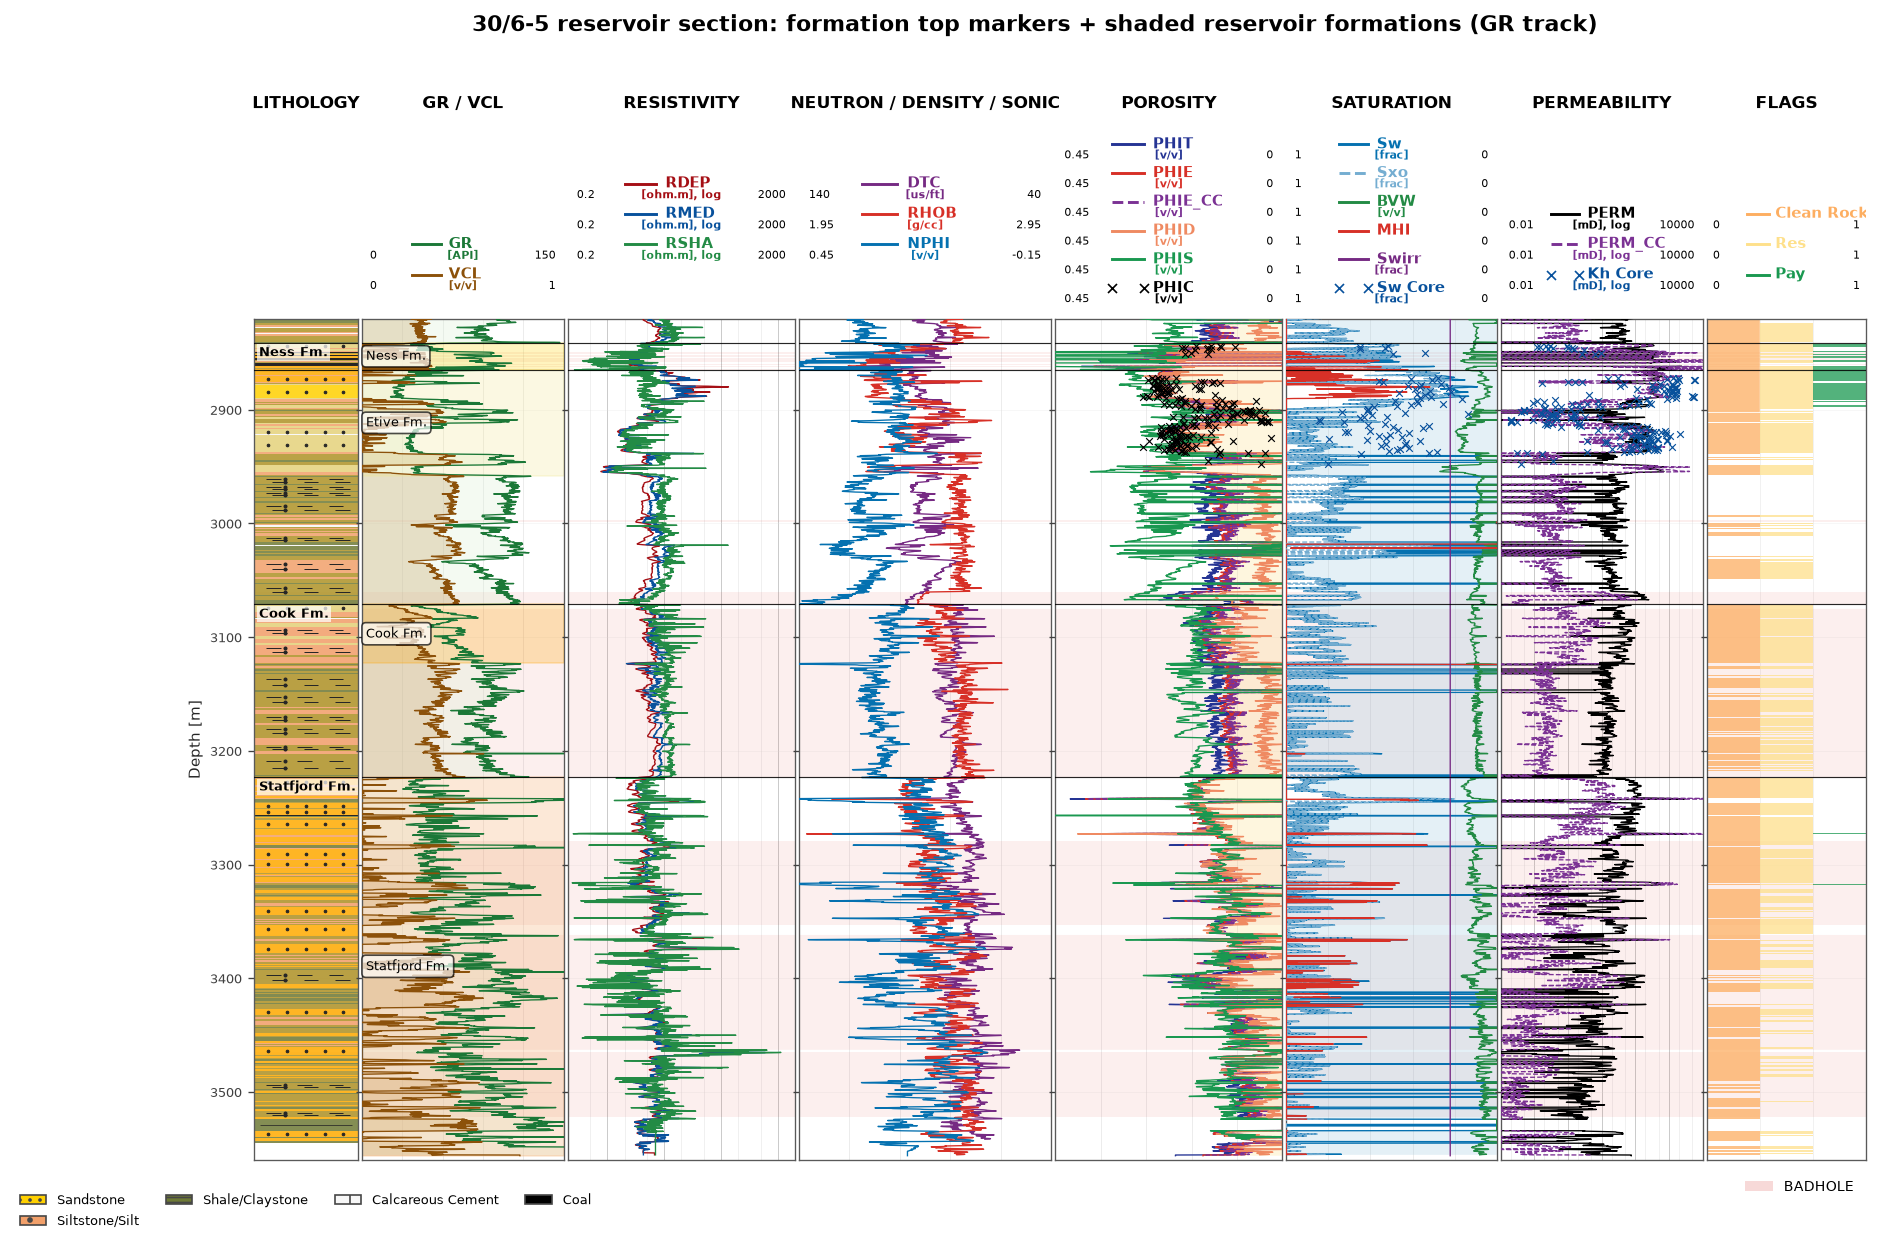

Label diagnostics: [{'name': 'Etive Fm.', 'depth': 2865.0, 'reason': 'label spacing'}]


In [16]:
palette = {"Ness Fm.": "gold", "Etive Fm.": "khaki",
           "Cook Fm.": "orange", "Statfjord Fm.": "sandybrown"}
shade = []
for name in RESERVOIR:
    iv = tops.get_by_name(name)
    if iv is not None:
        shade.append({"top": iv.top_depth, "bottom": iv.bottom_depth,
                      "name": iv.name, "color": palette[name]})

top_d, bot_d = 2820.0, 3560.0   # window covers all four shaded formations

# The "petrophysics" template renders GR, PHIE (POROSITY track) and the NET_PAY
# flag track. formation_tops= draws the named top MARKERS over every track;
# the actual colored shading is added below with add_zone_shading.
viewer = pp.plot(
    result,
    template="petrophysics",
    depth_range=(top_d, bot_d),
    formation_tops=shade,
    figsize=(14, 10),
)

# Real colored spans on the GR/VCL track: locate its data axis via the track
# header title, then paint the four reservoir formations.
gr_ax = next(ax for hax, ax in zip(viewer.header_axes, viewer.axes)
             if hax.texts and hax.texts[0].get_text().startswith("GR"))
add_zone_shading(gr_ax, shade, alpha=0.25)

_ = viewer.fig.suptitle(
    "30/6-5 reservoir section: formation top markers + shaded reservoir "
    "formations (GR track)", y=1.0)
viewer.show()
viewer.close()
print("Label diagnostics:", viewer.diagnostics["suppressed_formation_labels"])

The horizontal lines are formation tops; colored spans on the GR/VCL track are explicit zone shading. Coincident names are retained. Labels can still be suppressed when the window is crowded; inspect `viewer.diagnostics["suppressed_formation_labels"]` rather than assuming an unlabelled boundary was absent from the input.

## Pitfalls and parameter choices

- Net-pay cutoffs flag log values, not hydrocarbons. Shallow, poorly compacted
  sediments can pass them; report reservoir formations (or a reservoir depth
  window), not whole-well totals.
- Tops that mix groups and formations overlap. Pick one level with `rank=`, or
  rely on union totals; never add overlapping rows by hand.
- Supply or verify depth units, reference and datum. Compatible length units
  can be converted; MD/TVD and datum changes need real transformations.
- Missing metadata is a recorded assumption, not verified alignment.
- Declared rank/parent containment differs from an unlabelled overlap or a
  midpoint-derived parent label.
- Use explicit final bottoms or terminal depths for top-only analysis.
- Legacy IntervalAnalyzer/single-zone summaries are useful per interval, but
  their row sums are not hierarchy-aware union totals.
- Pay-averaged properties and the HCPV thickness index are not whole-interval
  statistics or volumetric OOIP.

## Recap

- `result.formation_summary(formations, rank="formation")` is the front-door
  per-formation report: thicknesses, NTG and pay-averaged properties.
- Shallow overburden can pass net-pay cutoffs; focus the report on the
  reservoir formations (here Ness, Etive, Cook, Statfjord).
- `FormationTops.from_csv` / `from_dataframe` load and query the interval
  geometry; the `Formation`/`Zone`/`SubZone` classes model the hierarchy.
- `IntervalAnalyzer` (and `analyze_interval`) give per-interval net pay, NTG,
  averages, dominant lithology, and coverage.
- `summarize_zones` rolls up an explicit zone list; `run_formation_analysis`
  is the end-to-end LAS -> workflow -> per-formation report.
- `add_zone_shading` paints named formation spans behind any depth track;
  `pp.plot(..., formation_tops=...)` draws top markers only.

## Try it yourself

> **Exercise 1.** Load the lithology CSV as `IntervalKind.ZONE` and run
> `IntervalAnalyzer.analyze_all` on it. Compare net pay bucketed by *lithology*
> against the formation buckets.
>
> **Exercise 2.** Add `Draupne Fm.` (a source-rock shale) to the shaded plot
> and look up its row in `by_formation`. Does it carry flagged pay, and what in
> its logs could make samples pass the cutoffs?
>
> **Exercise 3.** Re-run `pp.interpret` with `sw_cutoff=0.5` and compare
> `formation_summary(FM_CSV, rank="formation")` against the base run - which
> reservoir formations lose the most net pay?

## What's next

Continue with **12 - Core Calibration and the Digital Core** before treating
any interval summary as decision-ready. For file mapping, templates and error
handling, revisit [Your Own Data](../own_data.ipynb). Formation and lithology
inputs remain optional for the underlying interpretation workflow.